In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.neighbors import NearestNeighbors
from pathlib import Path

In [4]:
base_dir = Path().cwd().parent

dataset_path = base_dir/"Data"/"Mall_Customers.csv"

In [5]:
DF= pd.read_csv(dataset_path)
DF

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [6]:
DF.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [7]:
DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [8]:
DF.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [9]:
DF.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [10]:
DF.duplicated().sum()

np.int64(0)

In [11]:
DF.rename(columns={'Annual Income (k$)': 'Annual_Income', 'Spending Score (1-100)': 'Spending_Score'}, inplace=True)
DF.drop('CustomerID', axis=1, inplace=True)

In [12]:
DF.head()

,Gender,Age,Annual_Income,Spending_Score
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


In [14]:
le = LabelEncoder()
DF['Gender'] = le.fit_transform(DF['Gender'])

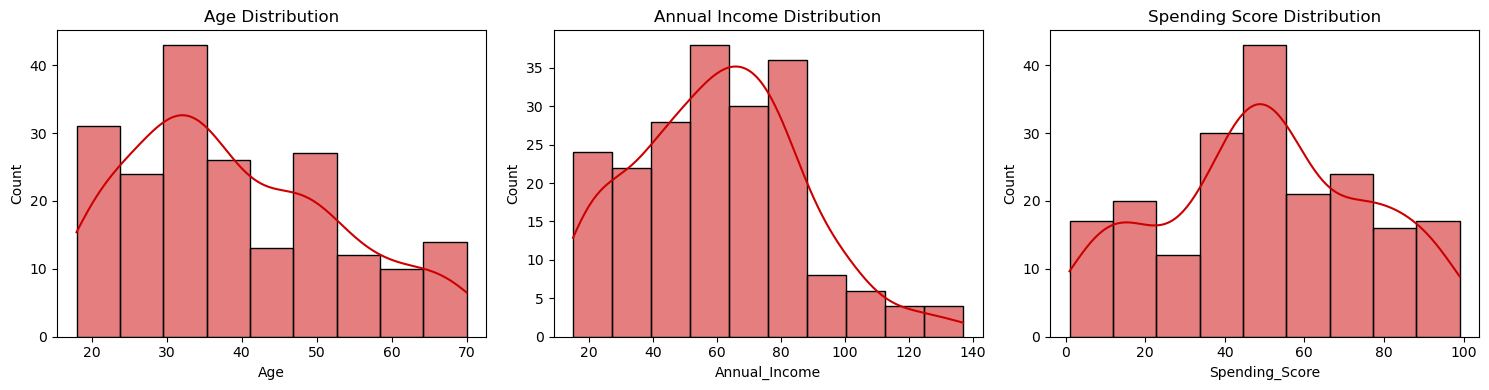

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(DF['Age'], kde=True, ax=axes[0], color='#CC0000').set_title('Age Distribution')
sns.histplot(DF['Annual_Income'], kde=True, ax=axes[1], color='#CC0000').set_title('Annual Income Distribution')
sns.histplot(DF['Spending_Score'], kde=True, ax=axes[2], color='#CC0000').set_title('Spending Score Distribution')
plt.tight_layout()
plt.show()

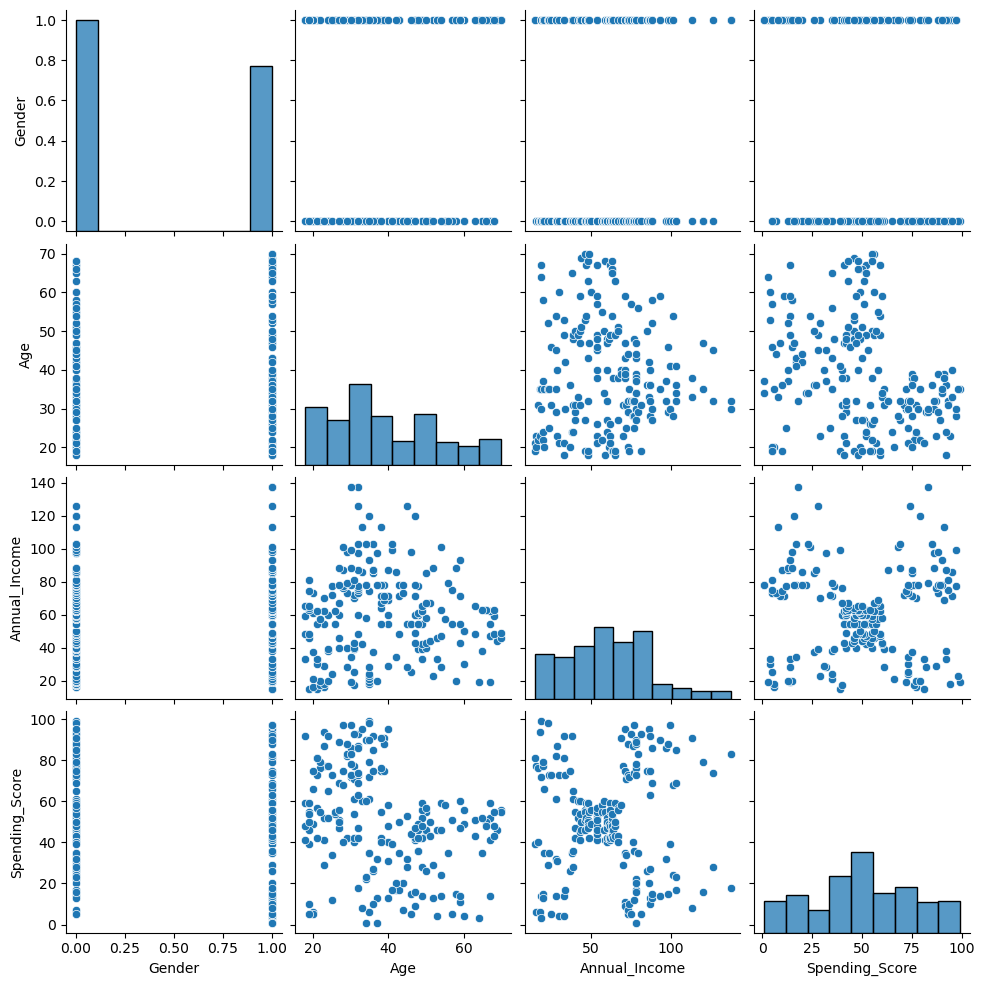

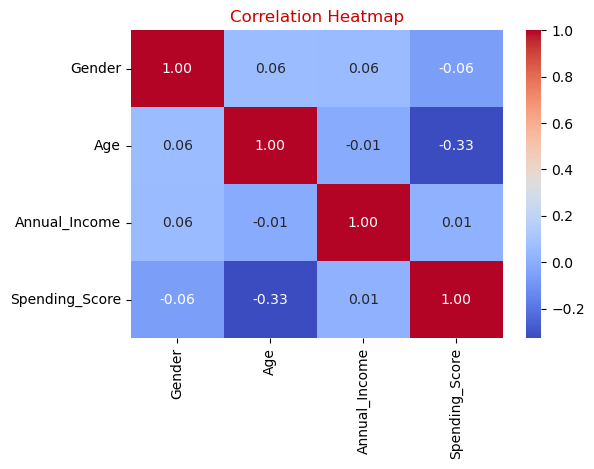

In [17]:
sns.pairplot(DF)
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(DF.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap', color='#CC0000')
plt.show()

In [18]:
scaler = StandardScaler()
DF_scaled = DF.copy()
DF_scaled[['Age', 'Annual_Income', 'Spending_Score']] = scaler.fit_transform(DF[['Age', 'Annual_Income', 'Spending_Score']])

In [19]:
DF_2f = DF_scaled[['Annual_Income', 'Spending_Score']]

In [20]:
inertias = []
sil_scores = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(DF_2f)
    inertias.append(km.inertia_)
    if k > 1:
        sil_scores.append(silhouette_score(DF_2f, km.labels_))

d:\Users\mantr\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\Users\mantr\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "d:\Users\mantr\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Users\mantr\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

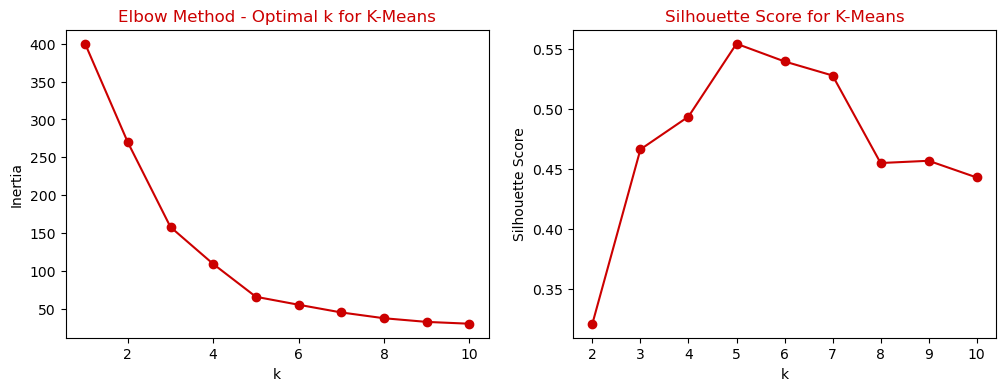

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 11), inertias, marker='o', color='#CC0000')
ax[0].set_title('Elbow Method - Optimal k for K-Means', color='#CC0000')
ax[0].set_xlabel('k')
ax[0].set_ylabel('Inertia')

ax[1].plot(range(2, 11), sil_scores, marker='o', color='#CC0000')
ax[1].set_title('Silhouette Score for K-Means', color='#CC0000')
ax[1].set_xlabel('k')
ax[1].set_ylabel('Silhouette Score')
plt.show()

In [23]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
DF['KMeans_Cluster'] = kmeans.fit_predict(DF_2f)

d:\Users\mantr\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


<Axes: xlabel='Annual_Income', ylabel='Spending_Score'>

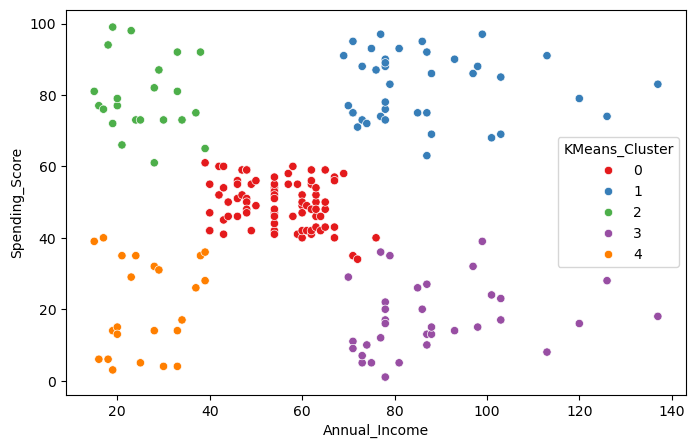

In [25]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans_Cluster', data=DF, palette='Set1')

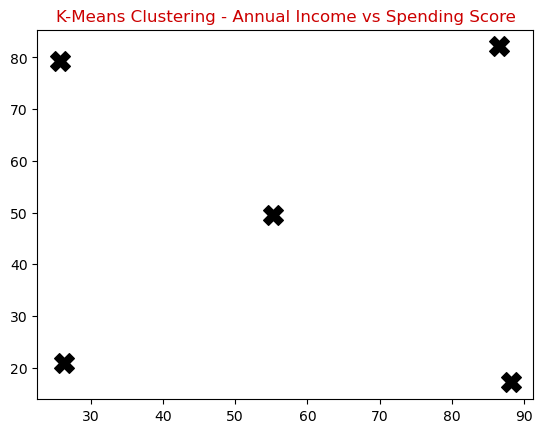

In [26]:
unscaled_centers = scaler.inverse_transform(np.c_[np.zeros(5), kmeans.cluster_centers_])
plt.scatter(unscaled_centers[:, 1], unscaled_centers[:, 2], c='black', marker='X', s=200)
plt.title('K-Means Clustering - Annual Income vs Spending Score', color='#CC0000')
plt.show()

In [28]:
kmeans_profile = DF.groupby('KMeans_Cluster')[['Age', 'Annual_Income', 'Spending_Score']].mean()
kmeans_profile.style.background_gradient(cmap='Blues')

,Age,Annual_Income,Spending_Score
KMeans_Cluster,,,
0,42.716049,55.296296,49.518519
1,32.692308,86.538462,82.128205
2,25.272727,25.727273,79.363636
3,41.114286,88.200000,17.114286
4,45.217391,26.304348,20.913043


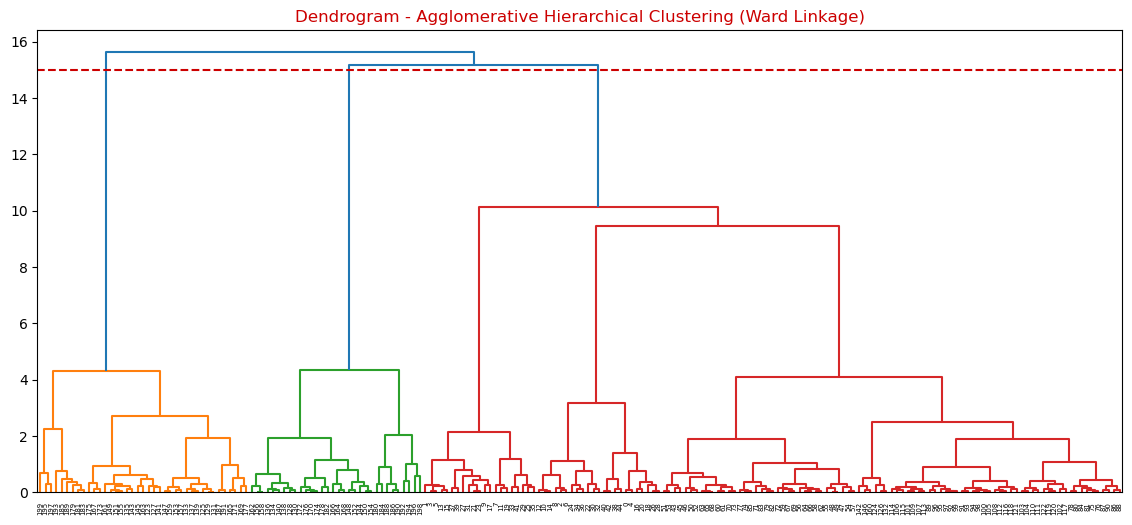

In [30]:
plt.figure(figsize=(14, 6))
linked = linkage(DF_2f, method='ward')
dendrogram(linked)
plt.axhline(y=15, color='#CC0000', linestyle='--')
plt.title('Dendrogram - Agglomerative Hierarchical Clustering (Ward Linkage)', color='#CC0000')
plt.show()

In [32]:
hc = AgglomerativeClustering(n_clusters=5, linkage='ward')
DF['Hier_Cluster'] = hc.fit_predict(DF_2f)

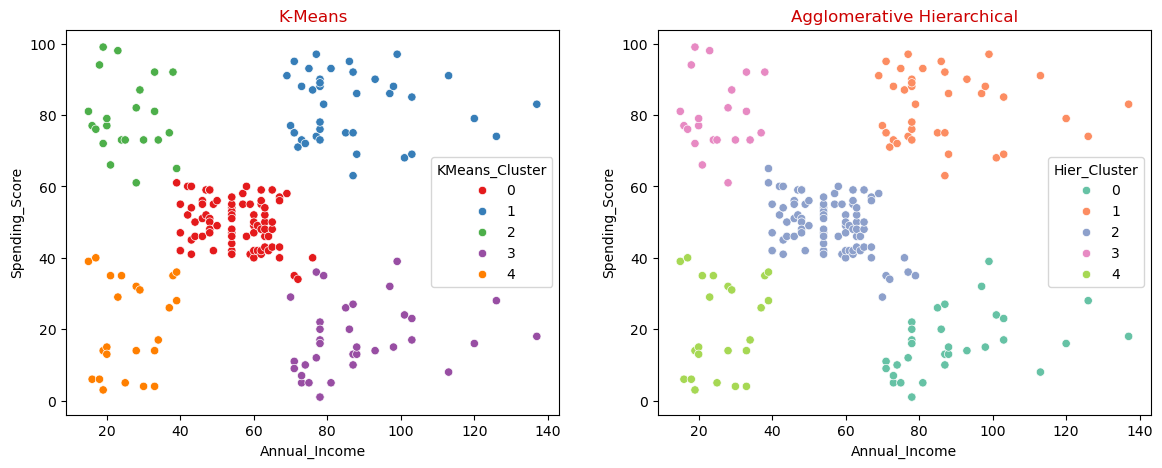

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans_Cluster', data=DF, palette='Set1', ax=ax[0])
ax[0].set_title('K-Means', color='#CC0000')
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Hier_Cluster', data=DF, palette='Set2', ax=ax[1])
ax[1].set_title('Agglomerative Hierarchical', color='#CC0000')
plt.show()

In [35]:
hier_profile = DF.groupby('Hier_Cluster')[['Age', 'Annual_Income', 'Spending_Score']].mean()
hier_profile.style.background_gradient(cmap='Greens')

,Age,Annual_Income,Spending_Score
Hier_Cluster,,,
0,41.000000,89.406250,15.593750
1,32.692308,86.538462,82.128205
2,42.482353,55.811765,49.129412
3,25.333333,25.095238,80.047619
4,45.217391,26.304348,20.913043


In [36]:
neigh = NearestNeighbors(n_neighbors=4)
nbrs = neigh.fit(DF_2f)
distances, _ = nbrs.kneighbors(DF_2f)
distances = np.sort(distances[:, 3], axis=0)

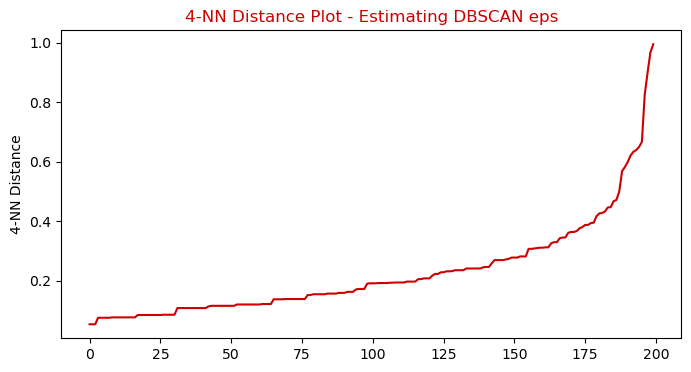

In [37]:
plt.figure(figsize=(8, 4))
plt.plot(distances, color='#CC0000')
plt.title('4-NN Distance Plot - Estimating DBSCAN eps', color='#CC0000')
plt.ylabel('4-NN Distance')
plt.show()

In [38]:
eps_vals = [0.2, 0.3, 0.4, 0.5, 0.6]
min_samples_vals = [3, 4, 5, 6]
results = []

for e in eps_vals:
    for ms in min_samples_vals:
        db = DBSCAN(eps=e, min_samples=ms).fit(DF_2f)
        labels = db.labels_
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        score = silhouette_score(DF_2f[labels != -1], labels[labels != -1]) if n_clusters > 1 else np.nan
        results.append({'eps': e, 'min_samples': ms, 'Clusters': n_clusters, 'Noise Points': n_noise, 'Silhouette': score})

db_df = pd.DataFrame(results).dropna().sort_values('Silhouette', ascending=False)
print(db_df.head())

   eps  min_samples  Clusters  Noise Points  Silhouette
1  0.2            4         5            73    0.617282
3  0.2            6         4            95    0.613836
2  0.2            5         7            77    0.585613
7  0.3            6         6            48    0.530244
6  0.3            5         7            35    0.524328


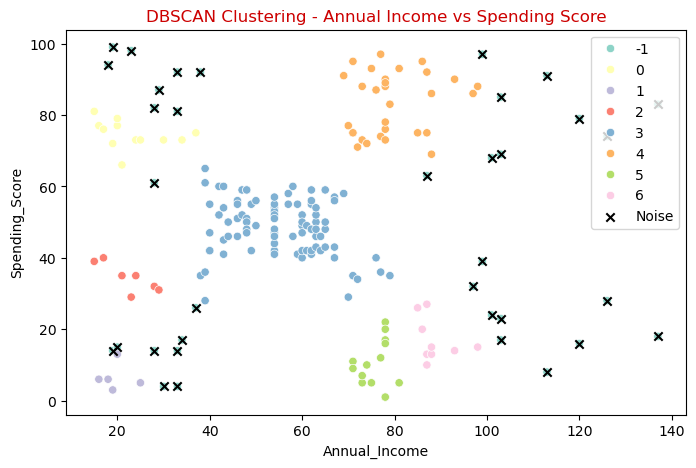

In [40]:
best_db = DBSCAN(eps=0.3, min_samples=5).fit(DF_2f)
DF['DBSCAN_Cluster'] = best_db.labels_

plt.figure(figsize=(8, 5))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='DBSCAN_Cluster', data=DF, palette='Set3')
noise = DF[DF['DBSCAN_Cluster'] == -1]
plt.scatter(noise['Annual_Income'], noise['Spending_Score'], c='black', marker='x', label='Noise')
plt.title('DBSCAN Clustering - Annual Income vs Spending Score', color='#CC0000')
plt.legend()
plt.show()

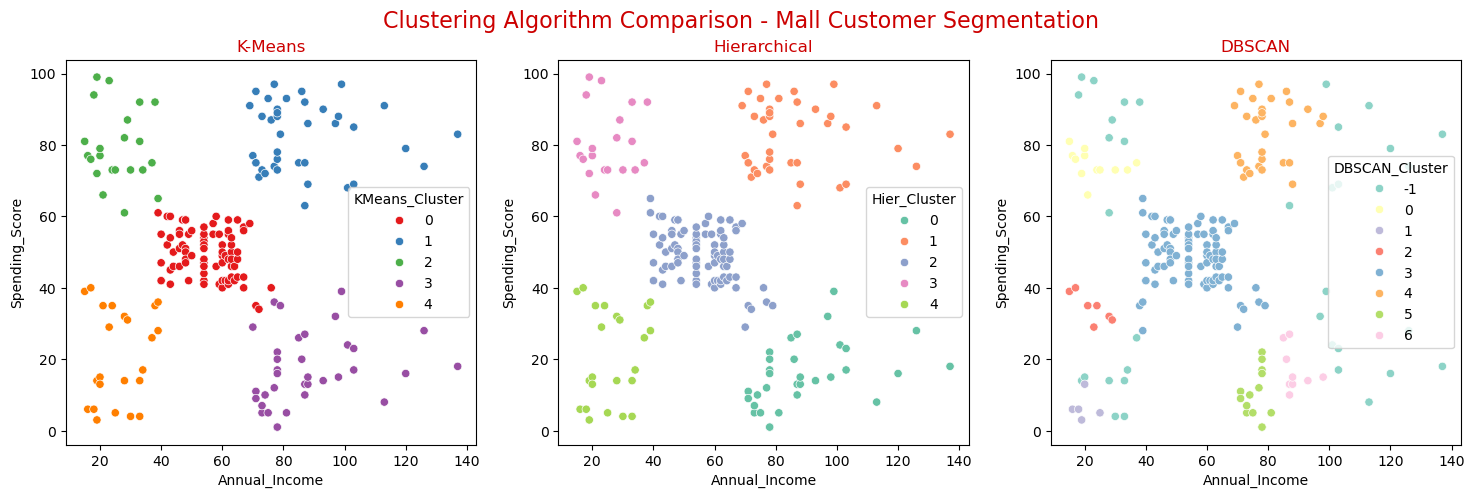

In [41]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans_Cluster', data=DF, palette='Set1', ax=ax[0])
ax[0].set_title('K-Means', color='#CC0000')
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Hier_Cluster', data=DF, palette='Set2', ax=ax[1])
ax[1].set_title('Hierarchical', color='#CC0000')
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='DBSCAN_Cluster', data=DF, palette='Set3', ax=ax[2])
ax[2].set_title('DBSCAN', color='#CC0000')
plt.suptitle('Clustering Algorithm Comparison - Mall Customer Segmentation', color='#CC0000', fontsize=16)
plt.show()

In [ ]:
metrics = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical', 'DBSCAN (eps=0.3, ms=5)'],
    'n_clusters': [5, 5, 7],
    'Silhouette Score': [
        silhouette_score(DF_2f, DF['KMeans_Cluster']),
        silhouette_score(DF_2f, DF['Hier_Cluster']),
        silhouette_score(DF_2f[DF['DBSCAN_Cluster'] != -1], DF.loc[DF['DBSCAN_Cluster'] != -1, 'DBSCAN_Cluster'])
    ]
})
display(metrics)

,Algorithm,n_clusters,Silhouette Score
0,K-Means,5,0.554657
1,Hierarchical,5,0.553809
2,"DBSCAN (eps=0.3, ms=5)",7,0.524328


### Business Insights for Mall Management

**A. Customer Segments (K-Means)**
1. **High Income, High Spenders:** Elite patrons buying premium goods.
2. **High Income, Low Spenders:** Frugal, affluent shoppers.
3. **Average Income, Average Spenders:** The mall's baseline demographic.
4. **Low Income, High Spenders:** Trend-driven or impulse shoppers.
5. **Low Income, Low Spenders:** Budget-conscious visitors.

**B. Marketing Actions**
* **High/High:** Exclusive VIP loyalty programs and personalized concierge services.
* **High/Low:** Targeted ads for high-ROI durable goods (tech, jewelry).
* **Average/Average:** Standard seasonal sales and bundled promotions.
* **Low/High:** Flash sales and limited-time offers to capture impulse buying.
* **Low/Low:** Deep discount marketing and clearance events.

**C. Algorithm Recommendation**
**K-Means** is recommended for deployment. Because customer spending habits here naturally form spherical clusters, K-Means captures all core segments perfectly without arbitrarily splintering the dense middle segment or isolating too many valuable edge customers as noise (which DBSCAN does). Its explicit centroid profiles make boundaries easy for the marketing team to interpret and action.